# Biomarkers on real segmentations — analysis

The configuration is on [biomarker-real-docs.md](../docs/benchmarks/biomarker-real-docs.md) and the
conclusions on [biomarker-real-results.md](../docs/benchmarks/biomarker-real-results.md). This
notebook is where the judgement behind them is made.

**The question.** Every biomarker is computed twice on each photograph: on the **expert's**
artery/vein map, and on a **segmentation model's** map of the same photograph. The program, the
optic disc, the field of view and the microns-per-pixel scale are the same both times, so any
difference between the two numbers comes from the vessel map alone. Two statistics summarise it:

- **ICC(A,1)**, the intraclass correlation for absolute agreement. Of the spread across
  photographs, how much is real difference between eyes rather than disagreement between the two
  maps? 1 is perfect. Below 0.75 a study could not use one map's numbers in place of the other's.
  **ICC(C,1)** is the same but forgives a constant offset.
- **SNR**, the signal-to-noise ratio. How much eyes differ (the SD across photographs on the
  expert's maps) over how much the model's map moves the number (the SD of model − expert). Below
  1, the segmentation error is larger than the differences between eyes the biomarker exists to
  detect.

The **model is the primary index** throughout, and the biomarker the secondary one. Every
statistic is read from the agreement tables the run wrote, under
`results/biomarker-real/<implementation>/agreement/`. Nothing here recomputes one, except where a
grouping the run does not make — a REYIA subset, say — needs one, and then it is computed by the
run's own function.

In [1]:
import csv
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(
        "this notebook has to be run from inside the fundus-atlas repository; "
        f"nothing above {Path.cwd()} looks like it"
    )


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_real as benchmark  # noqa: E402
from benchmarks.metrics import agreement  # noqa: E402
from biomarkers import canonical  # noqa: E402
from biomarkers.utils import catalogue  # noqa: E402

RESULTS = ROOT / "results" / benchmark.NAME
STORE = ROOT / ".atlas_data"
KEPT = ROOT / ".atlas_runs" / "av"
IMPLEMENTATIONS = [s for s in benchmark.IMPLEMENTATIONS if (RESULTS / s).is_dir()]
MODELS = list(benchmark.SEGMENTERS)
DATASETS = list(benchmark.DATASETS)
PANEL = dict(benchmark.PANEL)  # label -> catalogued name
REFERENCE = benchmark.REFERENCE
DECLARED = {slug: catalogue.load(slug).declare() for slug in IMPLEMENTATIONS}
Image.MAX_IMAGE_PIXELS = None

if not IMPLEMENTATIONS:
    raise SystemExit(f"nothing in {RESULTS}: run `python -m benchmarks --benchmark {benchmark.NAME}`")


def agreement_tables() -> pd.DataFrame:
    # Every agreement row the run wrote: per dataset, and pooled.
    frames = []
    for slug in IMPLEMENTATIONS:
        for path in sorted((RESULTS / slug / "agreement").glob("*.csv")):
            frame = pd.read_csv(path, keep_default_na=False, na_values=[""])
            frame.insert(0, "dataset", path.stem)
            frame.insert(0, "implementation", slug)
            frames.append(frame)
    found = pd.concat(frames, ignore_index=True)
    for column in ["icc_agreement", "icc_consistency", "snr", "iqr_mape", "iqr_pct", "mape_pct", "relative_bias", "n"]:
        found[column] = pd.to_numeric(found[column].replace("inf", np.inf), errors="coerce")
    found["family"] = found["name"].fillna("").str.split("/").str[0].replace("", "(unnamed)")
    return found


def evidence(slug: str, dataset: str) -> list[dict[str, str]]:
    path = RESULTS / slug / f"{dataset}.csv"
    with open(path, newline="") as f:
        return list(csv.DictReader(f))


def summaries() -> pd.DataFrame:
    rows = []
    for slug in IMPLEMENTATIONS:
        for path in sorted((RESULTS / slug).glob("*.json")):
            import json

            found = json.loads(path.read_text())["summary"]
            rows.append({"implementation": slug, "dataset": path.stem, **found})
    return pd.DataFrame(rows)


AGREE = agreement_tables()
SUMMARY = summaries()
POOLED = AGREE[AGREE["dataset"] == "pooled"]
PER_DATASET = AGREE[AGREE["dataset"] != "pooled"]
print(f"{len(IMPLEMENTATIONS)} implementations, {AGREE['column'].nunique()} distinct columns, "
      f"{len(AGREE)} agreement rows")

7 implementations, 747 distinct columns, 23190 agreement rows


## 1. Coverage

How much was measured before any agreement is read. One row per (implementation, dataset):
photographs, maps measured (the expert's plus one per model), maps on which the program returned
nothing at all, and whether the result is complete.

In [2]:
coverage = SUMMARY[["implementation", "dataset", "processed", "total", "maps", "failed", "complete"]]
coverage.pivot_table(index="implementation", columns="dataset", values="processed", aggfunc="first").reindex(IMPLEMENTATIONS)

dataset,avrdb,fundus-avseg,hrf,rav,reyia
implementation,,,,,
pvbm,99,100,45,198,554
ocular,99,100,45,198,554
automorph,99,100,45,198,554
automorphalyzer,99,100,45,198,554
automorphclass,99,100,45,198,554
vascx,99,100,45,198,554
fundus-biomarkers,99,100,45,198,554


In [3]:
coverage.set_index(["implementation", "dataset"]).loc[IMPLEMENTATIONS]

processed  total  maps  failed  complete
implementation    dataset                                               
pvbm              avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324       2      True
ocular            avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324       2      True
automorph         avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324       2      True
automorphalyzer   avrdb                99     99   594       2      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324      11      True
automorphclass    avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324       2      True
vascx             avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188       0      True
                  reyia               554    554  3324       0      True
fundus-biomarkers avrdb                99     99   594       0      True
                  fundus-avseg        100    100   600       0      True
                  hrf                  45     45   270       0      True
                  rav                 198    198  1188     258      True
                  reyia               554    554  3324     408      True

### 1.1 Where the model's map produced no number and the expert's did

For the headline panel, from the reference implementation. A biomarker missing on a model's map
is a different failure from one that is wrong, and is never folded into the ICC: `model_only` and
`expert_only` count the photographs where only one map produced a value.

In [4]:
panel_rows = POOLED[(POOLED["implementation"] == REFERENCE) & POOLED["name"].isin(PANEL.values())]
label_of = {name: label for label, name in PANEL.items()}
missing = panel_rows.assign(biomarker=panel_rows["name"].map(label_of)).pivot_table(
    index="model", columns="biomarker", values="expert_only", aggfunc="first"
).reindex(MODELS)[list(PANEL)]
missing

biomarker,CRAE,CRVE,AVR,Artery fractal dimension,Artery tortuosity
model,,,,,
vascx-artery-vein,0,1,0,0,0
ocularnet,0,1,0,0,0
lunet,0,1,0,0,0
automorph-artery-vein,7,4,7,3,5
bf-net,32,15,33,12,43


## 2. The headline panel

Five biomarkers a reader of a vascular-epidemiology paper is most likely to meet, each with its own
way of failing:

- **CRAE and CRVE** — Knudtson's central retinal artery and vein equivalents in zone B. They fail
  on a vessel's edge.
- **AVR** — their ratio. It fails on the artery/vein classification.
- **Artery fractal dimension** — box-counting over the arteries. It fails on the smallest vessels.
- **Artery tortuosity** — median arc-to-chord ratio. It fails on a broken centreline.

All from the reference implementation, fundus-biomarkers, which names every column it returns.
Section 4 compares the other implementations.

### 2.1 Pooled over every photograph

In [5]:
def panel_table(frame: pd.DataFrame, statistic: str) -> pd.DataFrame:
    rows = frame[(frame["implementation"] == REFERENCE) & frame["name"].isin(PANEL.values())]
    table = rows.assign(biomarker=rows["name"].map(label_of)).pivot_table(
        index="model", columns="biomarker", values=statistic, aggfunc="first"
    )
    return table.reindex(MODELS)[list(PANEL)]


pooled_panel = pd.concat(
    {
        "ICC(A,1)": panel_table(POOLED, "icc_agreement"),
        "ICC(C,1)": panel_table(POOLED, "icc_consistency"),
        "SNR": panel_table(POOLED, "snr"),
        "IQR/MAPE": panel_table(POOLED, "iqr_mape"),
        "bias, % of expert": 100 * panel_table(POOLED, "relative_bias"),
    },
    axis=1,
)
pooled_panel.round(2)

ICC(A,1)                                       \
biomarker                 CRAE  CRVE   AVR Artery fractal dimension   
model                                                                 
vascx-artery-vein         0.49  0.63  0.55                     0.38   
ocularnet                 0.83  0.87  0.73                     0.80   
lunet                     0.35  0.46  0.33                     0.41   
automorph-artery-vein     0.41  0.56  0.42                     0.31   
bf-net                    0.28  0.33  0.21                     0.10   

                                        ICC(C,1)              \
biomarker             Artery tortuosity     CRAE  CRVE   AVR   
model                                                          
vascx-artery-vein                  0.81     0.52  0.64  0.56   
ocularnet                          0.88     0.83  0.87  0.73   
lunet                              0.83     0.38  0.52  0.34   
automorph-artery-vein              0.80     0.46  0.60  0.43   
bf-net                             0.63     0.28  0.35  0.24   

                                                                  ...  \
biomarker             Artery fractal dimension Artery tortuosity  ...   
model                                                             ...   
vascx-artery-vein                         0.51              0.83  ...   
ocularnet                                 0.81              0.89  ...   
lunet                                     0.44              0.84  ...   
automorph-artery-vein                     0.38              0.80  ...   
bf-net                                    0.12              0.65  ...   

                      IQR/MAPE                                       \
biomarker                 CRAE  CRVE   AVR Artery fractal dimension   
model                                                                 
vascx-artery-vein         2.41  2.61  2.22                     1.84   
ocularnet                 3.07  3.42  2.77                     3.58   
lunet                     2.23  2.33  1.76                     2.15   
automorph-artery-vein     1.89  2.15  1.80                     1.85   
bf-net                    1.09  0.95  1.02                     1.26   

                                        bias, % of expert              \
biomarker             Artery tortuosity              CRAE  CRVE   AVR   
model                                                                   
vascx-artery-vein                  2.60             -5.95 -3.04 -2.33   
ocularnet                          3.41             -0.21  0.93 -0.83   
lunet                              3.02             -7.36 -7.91  2.08   
automorph-artery-vein              2.53             -9.34 -5.84 -3.46   
bf-net                             1.81             -0.78  7.41 -8.68   

                                                                  
biomarker             Artery fractal dimension Artery tortuosity  
model                                                             
vascx-artery-vein                        -2.96             -0.32  
ocularnet                                -0.61             -0.22  
lunet                                    -1.69             -0.21  
automorph-artery-vein                    -2.60             -0.16  
bf-net                                   -2.68             -0.29  

[5 rows x 25 columns]

### 2.2 Dataset by dataset

Pooling widens the signal: eyes from five cohorts and many cameras differ more than eyes from one,
so a pooled ICC flatters. These per-dataset figures are the primary evidence.

In [6]:
by_dataset = PER_DATASET[(PER_DATASET["implementation"] == REFERENCE) & PER_DATASET["name"].isin(PANEL.values())]
by_dataset = by_dataset.assign(biomarker=by_dataset["name"].map(label_of))
icc_by_dataset = by_dataset.pivot_table(
    index=["model", "dataset"], columns="biomarker", values="icc_agreement", aggfunc="first"
)[list(PANEL)]
icc_by_dataset = icc_by_dataset.reindex(
    pd.MultiIndex.from_product([MODELS, DATASETS], names=["model", "dataset"])
)
icc_by_dataset.round(2)

biomarker                           CRAE  CRVE   AVR  \
model                 dataset                          
vascx-artery-vein     hrf           0.53  0.31  0.66   
                      fundus-avseg  0.48  0.60  0.70   
                      avrdb         0.09  0.13  0.09   
                      reyia         0.80  0.84  0.75   
                      rav           0.87  0.89  0.47   
ocularnet             hrf           0.61  0.39  0.68   
                      fundus-avseg  0.60  0.72  0.78   
                      avrdb         0.39  0.51  0.41   
                      reyia         0.86  0.86  0.81   
                      rav           0.78  0.86  0.66   
lunet                 hrf           0.30  0.25  0.24   
                      fundus-avseg  0.33  0.47  0.69   
                      avrdb         0.07  0.09  0.13   
                      reyia         0.82  0.86  0.31   
                      rav           0.78  0.79  0.60   
automorph-artery-vein hrf           0.69  0.53  0.67   
                      fundus-avseg  0.30  0.34  0.74   
                      avrdb         0.07  0.10  0.03   
                      reyia         0.61  0.77  0.47   
                      rav           0.77  0.80  0.46   
bf-net                hrf           0.15  0.03  0.45   
                      fundus-avseg  0.51  0.48  0.53   
                      avrdb         0.09  0.19  0.03   
                      reyia         0.18  0.21  0.15   
                      rav           0.51  0.56  0.36   

biomarker                           Artery fractal dimension  \
model                 dataset                                  
vascx-artery-vein     hrf                               0.38   
                      fundus-avseg                      0.37   
                      avrdb                             0.02   
                      reyia                             0.80   
                      rav                               0.56   
ocularnet             hrf                               0.35   
                      fundus-avseg                      0.66   
                      avrdb                             0.13   
                      reyia                             0.95   
                      rav                               0.75   
lunet                 hrf                               0.29   
                      fundus-avseg                      0.42   
                      avrdb                             0.04   
                      reyia                             0.91   
                      rav                               0.63   
automorph-artery-vein hrf                               0.45   
                      fundus-avseg                      0.45   
                      avrdb                             0.01   
                      reyia                             0.69   
                      rav                               0.25   
bf-net                hrf                               0.16   
                      fundus-avseg                      0.58   
                      avrdb                             0.01   
                      reyia                             0.12   
                      rav                               0.28   

biomarker                           Artery tortuosity  
model                 dataset                          
vascx-artery-vein     hrf                        0.75  
                      fundus-avseg               0.88  
                      avrdb                      0.77  
                      reyia                      0.81  
                      rav                        0.74  
ocularnet             hrf                        0.79  
                      fundus-avseg               0.92  
                      avrdb                      0.81  
                      reyia                      0.86  
                      rav                        0.92  
lunet                 hrf                        0.74  
                      fundus-a

In [7]:
snr_by_dataset = by_dataset.pivot_table(
    index=["model", "dataset"], columns="biomarker", values="snr", aggfunc="first"
)[list(PANEL)].reindex(icc_by_dataset.index)
snr_by_dataset.round(2)

biomarker                           CRAE  CRVE   AVR  \
model                 dataset                          
vascx-artery-vein     hrf           1.47  1.03  1.51   
                      fundus-avseg  1.75  1.29  1.88   
                      avrdb         1.11  0.97  0.63   
                      reyia         1.54  1.76  1.41   
                      rav           2.07  2.14  0.91   
ocularnet             hrf           1.46  1.11  1.42   
                      fundus-avseg  2.20  1.67  2.24   
                      avrdb         1.38  1.38  1.06   
                      reyia         2.19  2.17  1.69   
                      rav           1.77  2.20  1.34   
lunet                 hrf           1.08  0.84  0.75   
                      fundus-avseg  1.81  1.68  1.63   
                      avrdb         1.03  1.01  0.43   
                      reyia         1.62  1.89  0.57   
                      rav           1.59  1.75  1.05   
automorph-artery-vein hrf           1.66  1.22  1.48   
                      fundus-avseg  1.28  1.11  2.00   
                      avrdb         0.92  0.95  0.64   
                      reyia         0.99  1.36  0.87   
                      rav           1.48  1.55  0.94   
bf-net                hrf           0.92  0.64  0.85   
                      fundus-avseg  0.97  1.10  1.07   
                      avrdb         0.67  0.60  0.63   
                      reyia         0.46  0.46  0.55   
                      rav           0.75  1.07  0.76   

biomarker                           Artery fractal dimension  \
model                 dataset                                  
vascx-artery-vein     hrf                               1.13   
                      fundus-avseg                      1.75   
                      avrdb                             0.98   
                      reyia                             2.21   
                      rav                               1.52   
ocularnet             hrf                               1.10   
                      fundus-avseg                      2.08   
                      avrdb                             1.07   
                      reyia                             3.03   
                      rav                               1.42   
lunet                 hrf                               1.27   
                      fundus-avseg                      1.57   
                      avrdb                             0.86   
                      reyia                             2.20   
                      rav                               1.18   
automorph-artery-vein hrf                               1.22   
                      fundus-avseg                      1.35   
                      avrdb                             0.58   
                      reyia                             1.40   
                      rav                               0.53   
bf-net                hrf                               1.01   
                      fundus-avseg                      0.91   
                      avrdb                             0.46   
                      reyia                             0.60   
                      rav                               0.51   

biomarker                           Artery tortuosity  
model                 dataset                          
vascx-artery-vein     hrf                        1.50  
                      fundus-avseg               1.94  
                      avrdb                      1.42  
                      reyia                      1.82  
                      rav                        1.61  
ocularnet             hrf                        1.65  
                      fundus-avseg               2.41  
                      avrdb                      1.88  
                      reyia                      2.08  
                      rav                        2.62  
lunet                 hrf                        1.72  
                      fundus-a

The same, as IQR/MAPE — fundus-biomarkers' own target metric (configuration page §1.2), so these
rows can be read beside that project's published figures. Unlike the SNR it counts a constant
offset as error; where the SNR is high and IQR/MAPE is low, the difference is a bias.

In [8]:
iqr_mape_by_dataset = by_dataset.pivot_table(
    index=["model", "dataset"], columns="biomarker", values="iqr_mape", aggfunc="first"
)[list(PANEL)].reindex(icc_by_dataset.index)
iqr_mape_by_dataset.round(2)

biomarker                           CRAE  CRVE   AVR  \
model                 dataset                          
vascx-artery-vein     hrf           1.59  1.52  2.20   
                      fundus-avseg  1.11  1.25  1.75   
                      avrdb         0.51  0.56  0.83   
                      reyia         2.80  3.24  2.62   
                      rav           3.72  3.74  2.35   
ocularnet             hrf           1.88  1.56  2.33   
                      fundus-avseg  1.36  1.61  2.17   
                      avrdb         1.20  1.51  1.41   
                      reyia         3.07  3.41  3.24   
                      rav           2.59  3.39  2.31   
lunet                 hrf           1.13  1.42  0.95   
                      fundus-avseg  0.81  0.93  1.64   
                      avrdb         0.44  0.40  0.70   
                      reyia         3.95  4.86  2.07   
                      rav           2.87  2.56  2.04   
automorph-artery-vein hrf           2.12  2.01  2.32   
                      fundus-avseg  0.85  0.88  1.96   
                      avrdb         0.48  0.53  0.81   
                      reyia         1.71  2.39  1.72   
                      rav           3.03  2.94  1.99   
bf-net                hrf           0.51  0.39  1.20   
                      fundus-avseg  1.56  1.03  1.37   
                      avrdb         0.57  0.81  0.66   
                      reyia         0.74  0.67  0.85   
                      rav           1.22  1.16  1.22   

biomarker                           Artery fractal dimension  \
model                 dataset                                  
vascx-artery-vein     hrf                               2.31   
                      fundus-avseg                      0.72   
                      avrdb                             0.26   
                      reyia                             2.84   
                      rav                               1.62   
ocularnet             hrf                               2.19   
                      fundus-avseg                      1.39   
                      avrdb                             0.57   
                      reyia                             5.65   
                      rav                               2.85   
lunet                 hrf                               1.61   
                      fundus-avseg                      0.88   
                      avrdb                             0.25   
                      reyia                             4.86   
                      rav                               1.93   
automorph-artery-vein hrf                               2.30   
                      fundus-avseg                      0.87   
                      avrdb                             0.27   
                      reyia                             2.74   
                      rav                               1.53   
bf-net                hrf                               0.99   
                      fundus-avseg                      1.29   
                      avrdb                             0.26   
                      reyia                             1.27   
                      rav                               1.00   

biomarker                           Artery tortuosity  
model                 dataset                          
vascx-artery-vein     hrf                        1.76  
                      fundus-avseg               2.84  
                      avrdb                      2.09  
                      reyia                      2.74  
                      rav                        2.91  
ocularnet             hrf                        2.11  
                      fundus-avseg               3.75  
                      avrdb                      2.38  
                      reyia                      3.46  
                      rav                        4.81  
lunet                 hrf                        2.10  
                      fundus-a

### 2.3 What each ICC is made of

Every photograph, expert-map value against model-map value, pooled, for each model and panel
biomarker. The diagonal is perfect agreement. Colours are datasets. One ICC can hide a tight cloud
with a few far-off photographs, or a constant offset (a cloud parallel to the diagonal). Lengths
are in microns, converted by the run's own rule.

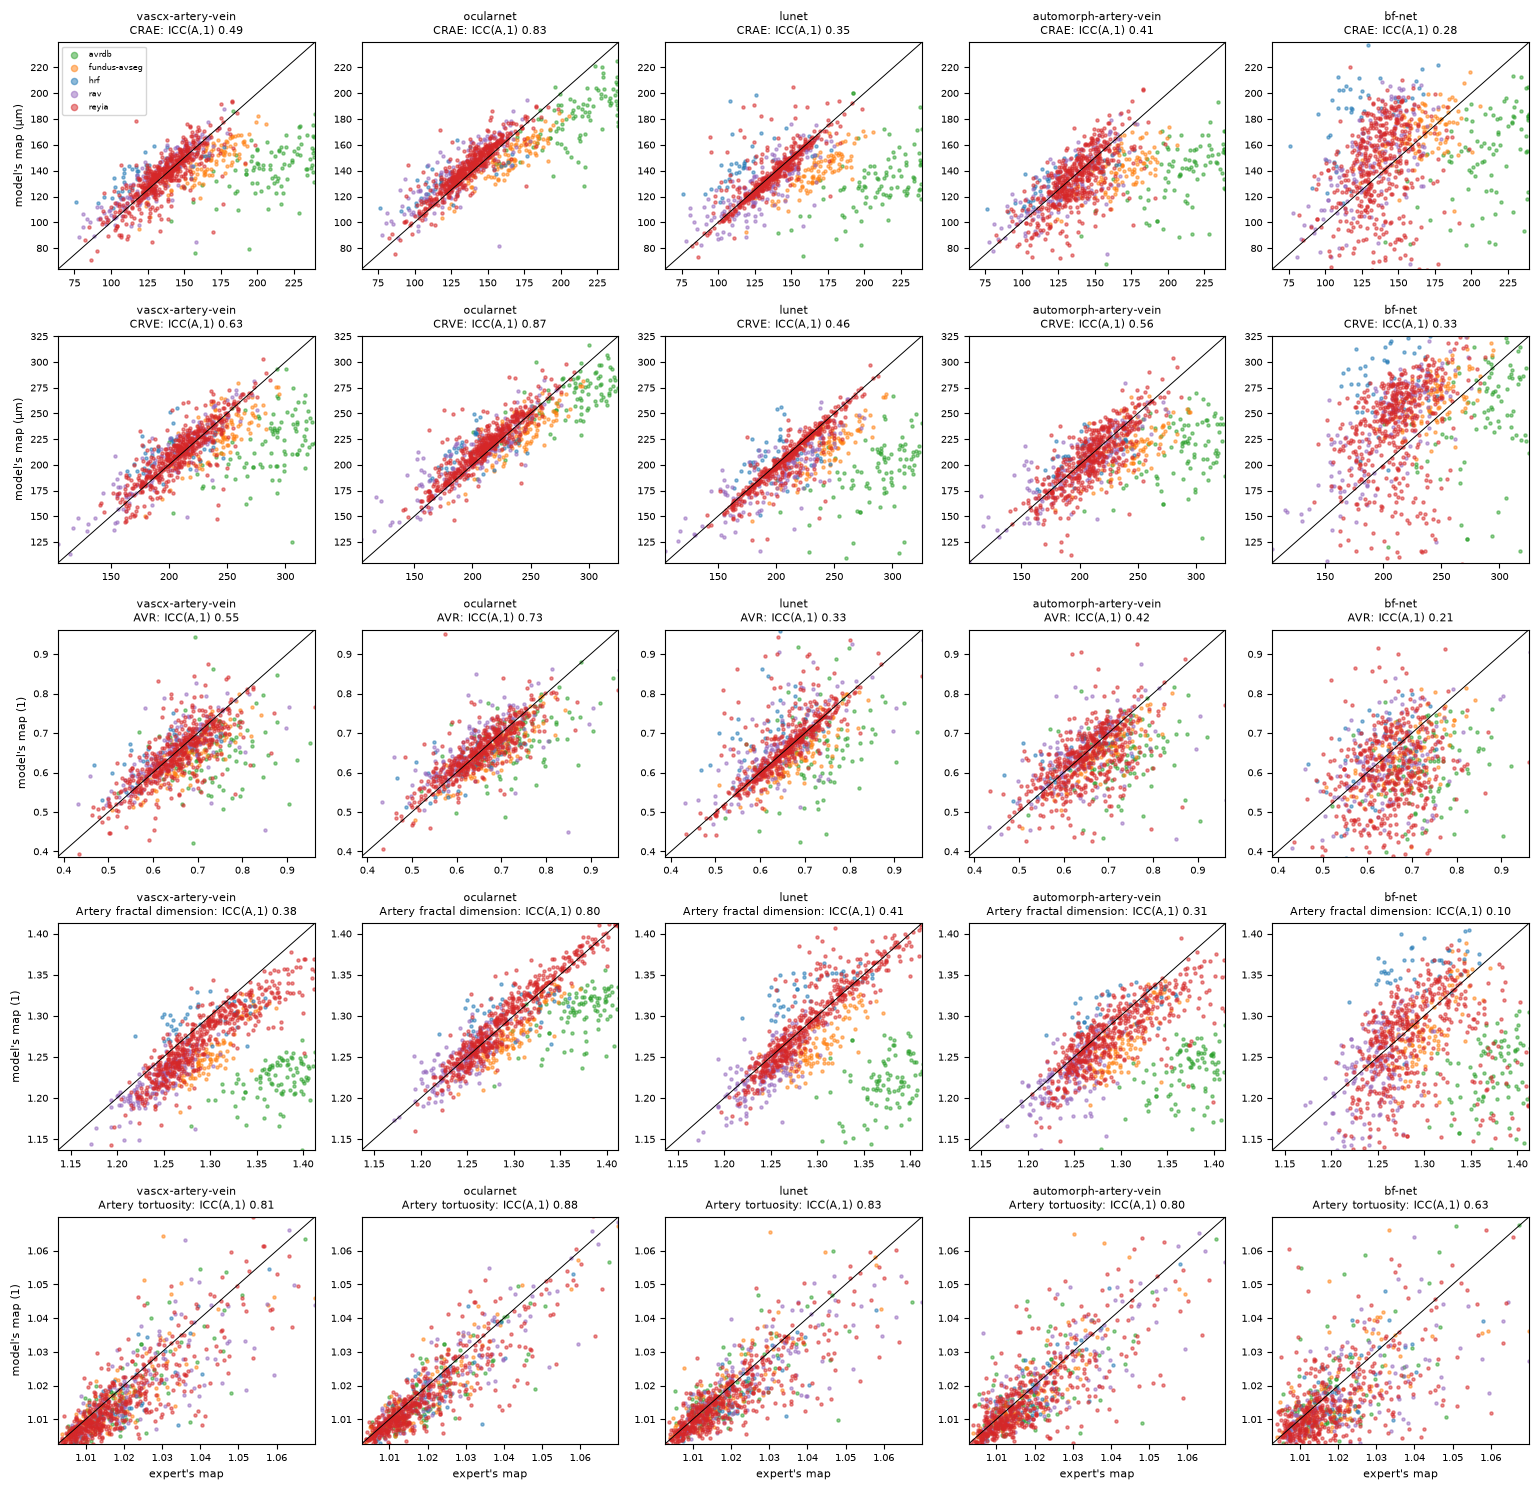

In [9]:
def paired_values(slug: str, name: str) -> pd.DataFrame:
    # Expert and model values for one catalogued name, every dataset, in the catalogued unit.
    declared = DECLARED[slug]
    owns = [own for own, catalogued in declared["names"].items() if catalogued == name]
    rows = []
    for dataset in DATASETS:
        if not (RESULTS / slug / f"{dataset}.csv").exists():
            continue
        table = benchmark._numbers(evidence(slug, dataset), declared)
        for own in owns:
            expert = table.get((benchmark.EXPERT, own), {})
            for model in MODELS:
                said = table.get((model, own), {})
                for key in set(expert) & set(said):
                    rows.append({"dataset": dataset, "model": model, "key": key,
                                 "expert": expert[key], "said": said[key]})
    return pd.DataFrame(rows)


PAIRS = {label: paired_values(REFERENCE, name) for label, name in PANEL.items()}
COLOURS = dict(zip(DATASETS, plt.cm.tab10.colors))

figure, axes = plt.subplots(len(PANEL), len(MODELS), figsize=(3.1 * len(MODELS), 3.0 * len(PANEL)))
for row, (label, pairs) in enumerate(PAIRS.items()):
    if pairs.empty:
        continue
    low, high = np.nanpercentile(np.r_[pairs["expert"], pairs["said"]], [0.5, 99.5])
    for column, model in enumerate(MODELS):
        axis = axes[row, column]
        mine = pairs[pairs["model"] == model]
        for dataset, group in mine.groupby("dataset"):
            axis.scatter(group["expert"], group["said"], s=5, alpha=0.5, color=COLOURS[dataset], label=dataset)
        axis.plot([low, high], [low, high], color="black", linewidth=0.7)
        axis.set_xlim(low, high)
        axis.set_ylim(low, high)
        icc = pooled_panel.loc[model, ("ICC(A,1)", label)]
        axis.set_title(f"{model}\n{label}: ICC(A,1) {icc:.2f}", fontsize=8)
        if column == 0:
            unit = canonical.unit(PANEL[label])
            axis.set_ylabel(f"model's map ({unit})", fontsize=8)
        if row == len(PANEL) - 1:
            axis.set_xlabel("expert's map", fontsize=8)
        axis.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=6, markerscale=2)
figure.tight_layout()
plt.show()

### 2.4 Difference against mean (Bland–Altman)

The same pairs, as model − expert against their mean, so a bias that grows with the value — a
model that thins the widest vessels most, say — shows as a slope rather than a cloud. The dashed
lines are the bias and its 95% limits of agreement (bias ± 1.96 SD of the difference).

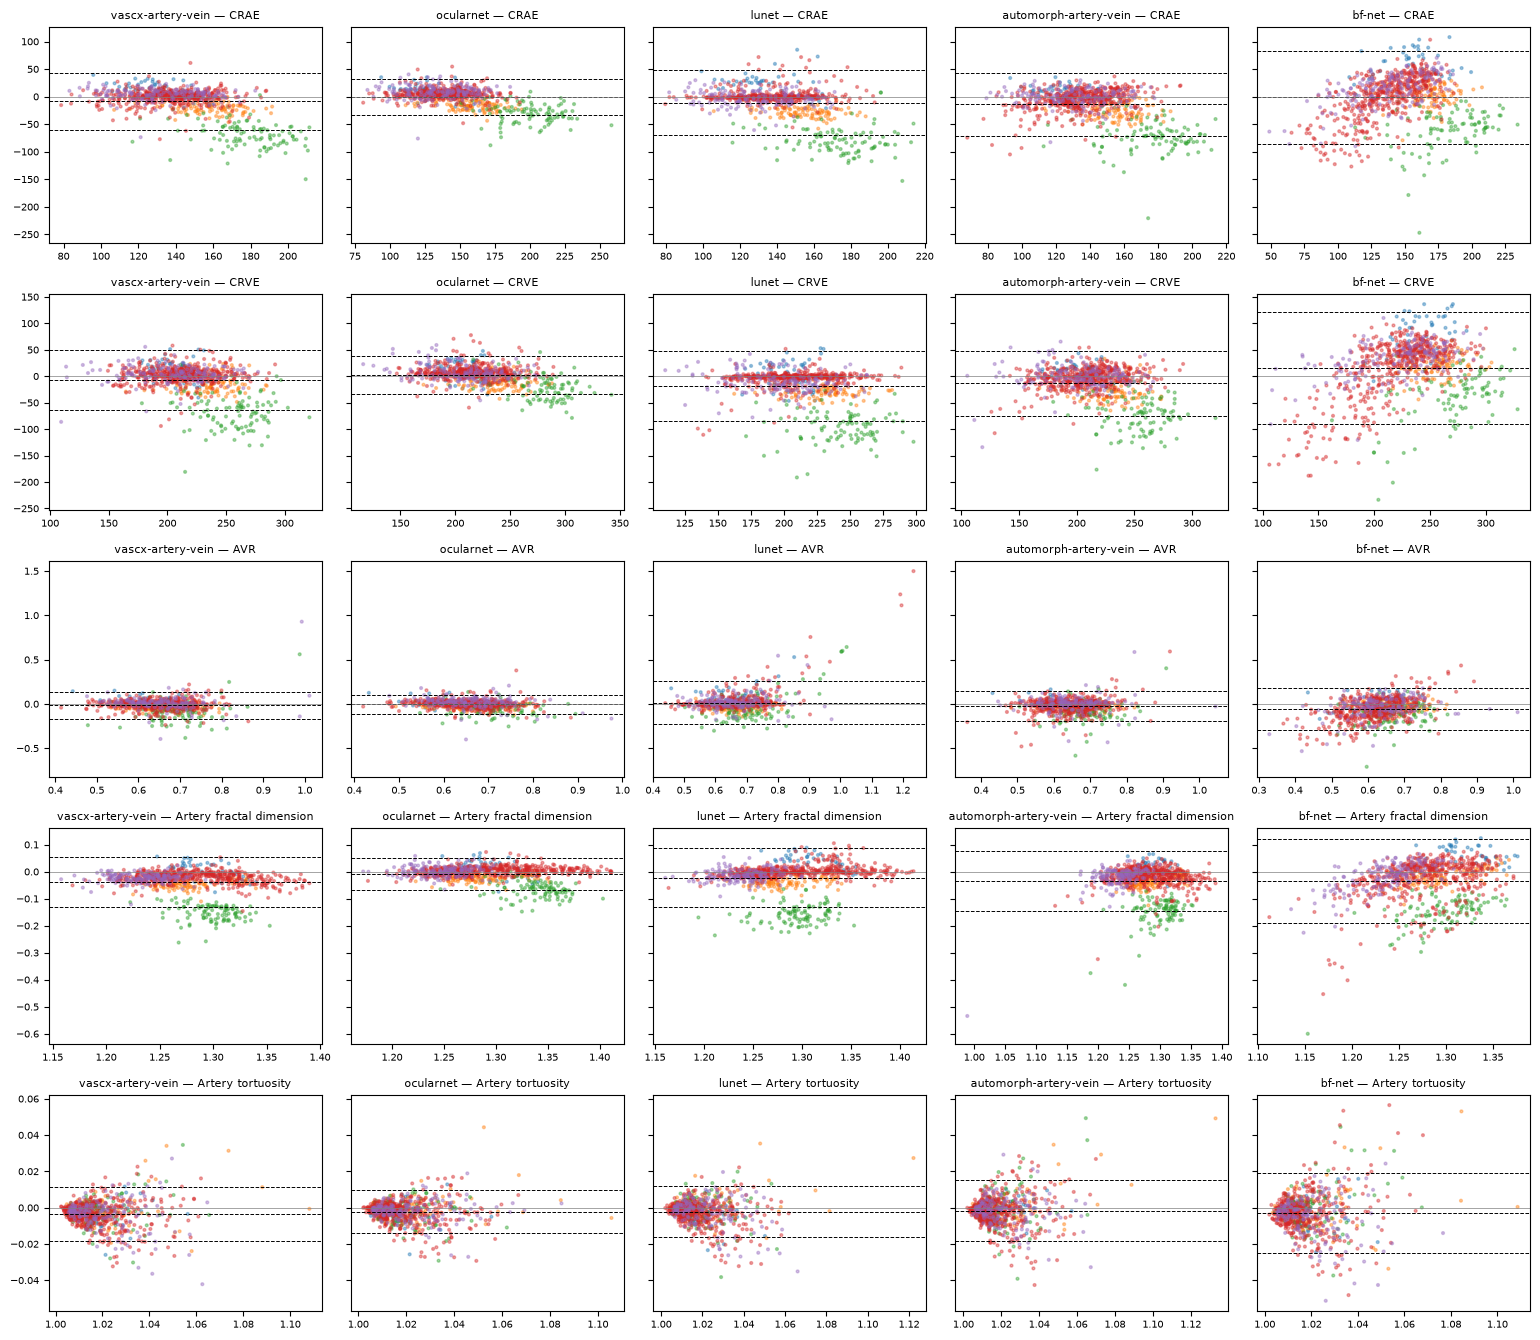

In [10]:
figure, axes = plt.subplots(len(PANEL), len(MODELS), figsize=(3.1 * len(MODELS), 2.7 * len(PANEL)), sharey="row")
for row, (label, pairs) in enumerate(PAIRS.items()):
    for column, model in enumerate(MODELS):
        axis = axes[row, column]
        mine = pairs[pairs["model"] == model]
        if mine.empty:
            continue
        mean = (mine["expert"] + mine["said"]) / 2
        difference = mine["said"] - mine["expert"]
        axis.scatter(mean, difference, s=4, alpha=0.4, color=[COLOURS[d] for d in mine["dataset"]])
        bias, spread = difference.mean(), difference.std()
        for level in (bias, bias - 1.96 * spread, bias + 1.96 * spread):
            axis.axhline(level, color="black", linestyle="--", linewidth=0.7)
        axis.axhline(0, color="grey", linewidth=0.5)
        axis.set_title(f"{model} — {label}", fontsize=8)
        axis.tick_params(labelsize=7)
figure.tight_layout()
plt.show()

## 3. Every catalogued biomarker

The panel is five numbers out of hundreds. Here every catalogued column the reference
implementation returns, grouped by family: the distribution of pooled ICC(A,1), SNR and IQR/MAPE per model.
A family whose box sits high survives a model's map. One that sits low does not, whatever the model.

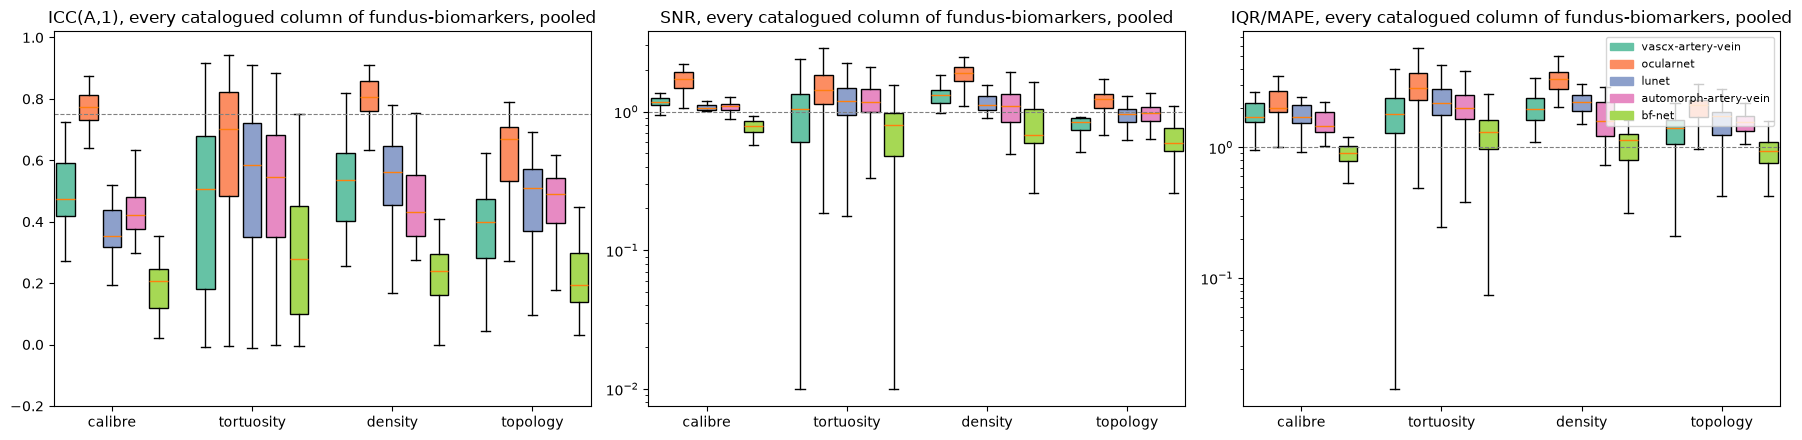

In [11]:
named = POOLED[(POOLED["implementation"] == REFERENCE) & POOLED["name"].notna() & (POOLED["n"] >= 20)]
families = [f for f in canonical.FAMILIES if f in set(named["family"])]

figure, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for axis, statistic, title in (
    (axes[0], "icc_agreement", "ICC(A,1)"), (axes[1], "snr", "SNR"), (axes[2], "iqr_mape", "IQR/MAPE")
):
    positions, data, labels = [], [], []
    for index, family in enumerate(families):
        for offset, model in enumerate(MODELS):
            values = named[(named["family"] == family) & (named["model"] == model)][statistic]
            values = values.replace(np.inf, np.nan).dropna()
            if statistic != "icc_agreement":
                values = values.clip(lower=0.01, upper=20)
            positions.append(index * (len(MODELS) + 1) + offset)
            # An empty group still holds its place, or every box after it shifts one family along.
            data.append(values.to_numpy() if len(values) else np.array([np.nan]))
    # One box at a time: handed a list of equal-length arrays, matplotlib reads it as one 2-D array.
    for values, position in zip(data, positions):
        box = axis.boxplot([values], positions=[position], widths=0.8, showfliers=False, patch_artist=True)
        box["boxes"][0].set_facecolor(plt.cm.Set2.colors[position % (len(MODELS) + 1)])
    axis.set_xticks([i * (len(MODELS) + 1) + (len(MODELS) - 1) / 2 for i in range(len(families))])
    axis.set_xticklabels(families)
    axis.set_title(f"{title}, every catalogued column of {REFERENCE}, pooled")
    if statistic == "icc_agreement":
        axis.axhline(0.75, color="grey", linestyle="--", linewidth=0.8)
        axis.set_ylim(-0.2, 1.02)
    else:
        axis.axhline(1, color="grey", linestyle="--", linewidth=0.8)
        axis.set_yscale("log")
handles = [plt.Rectangle((0, 0), 1, 1, color=plt.cm.Set2.colors[i]) for i in range(len(MODELS))]
axes[2].legend(handles, MODELS, fontsize=8, loc="upper right")
figure.tight_layout()
plt.show()

In [12]:
family_medians = named.pivot_table(index="model", columns="family", values="icc_agreement", aggfunc="median").reindex(MODELS)[families]
family_share = named.assign(good=named["icc_agreement"] >= 0.75).pivot_table(
    index="model", columns="family", values="good", aggfunc="mean").reindex(MODELS)[families]
pd.concat({"median ICC(A,1)": family_medians, "share with ICC(A,1) ≥ 0.75": family_share}, axis=1).round(2)

median ICC(A,1)                              \
family                        calibre tortuosity density topology   
model                                                               
vascx-artery-vein                0.48       0.50    0.54     0.40   
ocularnet                        0.77       0.70    0.81     0.67   
lunet                            0.35       0.59    0.56     0.51   
automorph-artery-vein            0.42       0.55    0.43     0.49   
bf-net                           0.21       0.28    0.24     0.19   

                      share with ICC(A,1) ≥ 0.75                              
family                                   calibre tortuosity density topology  
model                                                                         
vascx-artery-vein                           0.00       0.15    0.05     0.00  
ocularnet                                   0.59       0.40    0.77     0.08  
lunet                                       0.00       0.21    0.05     0.00  
automorph-artery-vein                       0.00       0.17    0.02     0.00  
bf-net                                      0.00       0.00    0.00     0.00

### 3.1 Which biomarkers survive every model, and which survive none

The catalogued columns whose pooled ICC(A,1) is at least 0.9 under **every** model, and those under
0.5 under every model. The first are safe to take from any of these maps. For the second, the
expert's tracing carries information no model reproduces — or the biomarker is too noisy on
anyone's map.

In [13]:
wide = named.pivot_table(index="name", columns="model", values="icc_agreement", aggfunc="first").reindex(columns=MODELS)
robust = wide[(wide >= 0.9).all(axis=1)]
fragile = wide[(wide < 0.5).all(axis=1)]
print(f"{len(robust)} of {len(wide)} catalogued columns at ICC(A,1) ≥ 0.9 under every model; "
      f"{len(fragile)} under 0.5 under every model")
robust.round(2).head(40)

0 of 629 catalogued columns at ICC(A,1) ≥ 0.9 under every model; 133 under 0.5 under every model


model,vascx-artery-vein,ocularnet,lunet,automorph-artery-vein,bf-net
name,,,,,


In [14]:
fragile.round(2).head(40)

model,vascx-artery-vein,ocularnet,lunet,automorph-artery-vein,bf-net
name,,,,,
topology/branching-angle/artery/B/std,0.24,0.39,0.35,0.33,0.16
topology/branching-angle/artery/std,0.25,0.47,0.29,0.18,0.03
topology/components/artery,0.04,0.27,0.10,0.16,0.04
topology/components/vein,0.06,0.30,0.13,0.13,0.03
topology/endpoints/artery/B,0.14,0.26,0.21,0.18,0.06
topology/endpoints/artery/C,0.26,0.44,0.29,0.40,0.08
topology/endpoints/vein/B,0.26,0.43,0.26,0.27,0.10
tortuosity/arc-chord-times-inflections/vein/B/median,0.30,0.29,0.28,0.25,0.15
tortuosity/arc-chord-times-inflections/vein/C/median,0.39,0.49,0.43,0.36,0.26


## 4. Where the implementations disagree

The same biomarker, the same model's map, different programs. Each panel biomarker is shown for
every implementation whose naming table claims it. Where one program is robust and another fragile
on the same pair of maps, the difference is in the program's tracing and measuring, not in the
model.

In [15]:
def implementations_on(name_prefix: str) -> pd.DataFrame:
    rows = POOLED[POOLED["name"].fillna("").str.startswith(name_prefix)]
    return rows.pivot_table(index=["implementation", "name"], columns="model", values="icc_agreement", aggfunc="first").reindex(columns=MODELS)


for label, name in PANEL.items():
    stem = "/".join(name.split("/")[:3])
    table = implementations_on(stem)
    print(f"\n{label} — every implementation's column under {stem}, pooled ICC(A,1)")
    display(table.round(2))


CRAE — every implementation's column under calibre/CRE-knudtson/artery, pooled ICC(A,1)


model                                            vascx-artery-vein  ocularnet  \
implementation    name                                                          
automorphalyzer   calibre/CRE-knudtson/artery/B               0.60       0.86   
fundus-biomarkers calibre/CRE-knudtson/artery/B               0.49       0.83   
                  calibre/CRE-knudtson/artery/C               0.51       0.83   
pvbm              calibre/CRE-knudtson/artery/B               0.08       0.17   
vascx             calibre/CRE-knudtson/artery/B               0.56       0.85   

model                                            lunet  automorph-artery-vein  \
implementation    name                                                          
automorphalyzer   calibre/CRE-knudtson/artery/B   0.44                   0.57   
fundus-biomarkers calibre/CRE-knudtson/artery/B   0.35                   0.41   
                  calibre/CRE-knudtson/artery/C   0.34                   0.40   
pvbm              calibre/CRE-knudtson/artery/B   0.12                   0.08   
vascx             calibre/CRE-knudtson/artery/B   0.40                   0.50   

model                                            bf-net  
implementation    name                                   
automorphalyzer   calibre/CRE-knudtson/artery/B    0.39  
fundus-biomarkers calibre/CRE-knudtson/artery/B    0.28  
                  calibre/CRE-knudtson/artery/C    0.26  
pvbm              calibre/CRE-knudtson/artery/B    0.06  
vascx             calibre/CRE-knudtson/artery/B    0.33


CRVE — every implementation's column under calibre/CRE-knudtson/vein, pooled ICC(A,1)


model                                          vascx-artery-vein  ocularnet  \
implementation    name                                                        
automorphalyzer   calibre/CRE-knudtson/vein/B               0.71       0.88   
fundus-biomarkers calibre/CRE-knudtson/vein/B               0.63       0.87   
                  calibre/CRE-knudtson/vein/C               0.63       0.87   
pvbm              calibre/CRE-knudtson/vein/B               0.07       0.25   
vascx             calibre/CRE-knudtson/vein/B               0.63       0.85   

model                                          lunet  automorph-artery-vein  \
implementation    name                                                        
automorphalyzer   calibre/CRE-knudtson/vein/B   0.57                   0.63   
fundus-biomarkers calibre/CRE-knudtson/vein/B   0.46                   0.56   
                  calibre/CRE-knudtson/vein/C   0.49                   0.57   
pvbm              calibre/CRE-knudtson/vein/B   0.29                   0.19   
vascx             calibre/CRE-knudtson/vein/B   0.49                   0.53   

model                                          bf-net  
implementation    name                                 
automorphalyzer   calibre/CRE-knudtson/vein/B    0.43  
fundus-biomarkers calibre/CRE-knudtson/vein/B    0.33  
                  calibre/CRE-knudtson/vein/C    0.35  
pvbm              calibre/CRE-knudtson/vein/B    0.06  
vascx             calibre/CRE-knudtson/vein/B    0.33


AVR — every implementation's column under calibre/AVR-knudtson/both, pooled ICC(A,1)


model                                          vascx-artery-vein  ocularnet  \
implementation    name                                                        
fundus-biomarkers calibre/AVR-knudtson/both/B               0.55       0.73   
                  calibre/AVR-knudtson/both/C               0.60       0.74   
pvbm              calibre/AVR-knudtson/both/B               0.02       0.13   

model                                          lunet  automorph-artery-vein  \
implementation    name                                                        
fundus-biomarkers calibre/AVR-knudtson/both/B   0.33                   0.42   
                  calibre/AVR-knudtson/both/C   0.36                   0.47   
pvbm              calibre/AVR-knudtson/both/B   0.11                   0.10   

model                                          bf-net  
implementation    name                                 
fundus-biomarkers calibre/AVR-knudtson/both/B    0.21  
                  calibre/AVR-knudtson/both/C    0.23  
pvbm              calibre/AVR-knudtson/both/B   -0.02


Artery fractal dimension — every implementation's column under density/box-counting/artery, pooled ICC(A,1)


model                                            vascx-artery-vein  ocularnet  \
implementation    name                                                          
automorph         density/box-counting/artery                 0.48       0.79   
automorphalyzer   density/box-counting/artery                 0.73       0.89   
automorphclass    density/box-counting/artery                 0.72       0.88   
fundus-biomarkers density/box-counting/artery                 0.38       0.80   
                  density/box-counting/artery/B               0.62       0.81   
                  density/box-counting/artery/C               0.52       0.81   

model                                            lunet  automorph-artery-vein  \
implementation    name                                                          
automorph         density/box-counting/artery     0.65                   0.37   
automorphalyzer   density/box-counting/artery     0.82                   0.57   
automorphclass    density/box-counting/artery     0.82                   0.52   
fundus-biomarkers density/box-counting/artery     0.41                   0.31   
                  density/box-counting/artery/B   0.57                   0.58   
                  density/box-counting/artery/C   0.45                   0.40   

model                                            bf-net  
implementation    name                                   
automorph         density/box-counting/artery      0.19  
automorphalyzer   density/box-counting/artery      0.32  
automorphclass    density/box-counting/artery      0.31  
fundus-biomarkers density/box-counting/artery      0.10  
                  density/box-counting/artery/B    0.30  
                  density/box-counting/artery/C    0.17


Artery tortuosity — every implementation's column under tortuosity/hart-tau1/artery, pooled ICC(A,1)


model                                                            vascx-artery-vein  \
implementation    name                                                               
automorph         tortuosity/hart-tau1/artery/mean                            0.48   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean                          0.51   
                  tortuosity/hart-tau1/artery/mean                            0.46   
automorphclass    tortuosity/hart-tau1/artery/length-weighted                 0.48   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted               0.34   
                  tortuosity/hart-tau1/artery/B/mean                          0.30   
                  tortuosity/hart-tau1/artery/B/median                        0.76   
                  tortuosity/hart-tau1/artery/B/std                           0.13   
                  tortuosity/hart-tau1/artery/C/length-weighted               0.48   
                  tortuosity/hart-tau1/artery/C/mean                          0.39   
                  tortuosity/hart-tau1/artery/C/median                        0.77   
                  tortuosity/hart-tau1/artery/C/std                           0.07   
                  tortuosity/hart-tau1/artery/length-weighted                 0.39   
                  tortuosity/hart-tau1/artery/mean                            0.45   
                  tortuosity/hart-tau1/artery/median                          0.81   
                  tortuosity/hart-tau1/artery/std                             0.09   
ocular            tortuosity/hart-tau1/artery/length-weighted                 0.61   
                  tortuosity/hart-tau1/artery/median                          0.65   
pvbm              tortuosity/hart-tau1/artery/median                          0.65   
vascx             tortuosity/hart-tau1/artery/length-weighted                 0.71   

model                                                            ocularnet  \
implementation    name                                                       
automorph         tortuosity/hart-tau1/artery/mean                    0.52   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean                  0.56   
                  tortuosity/hart-tau1/artery/mean                    0.52   
automorphclass    tortuosity/hart-tau1/artery/length-weighted         0.64   
fundus-biomarkers tortuosity/hart-tau1/artery/B/length-weighted       0.49   
                  tortuosity/hart-tau1/artery/B/mean                  0.56   
                  tortuosity/hart-tau1/artery/B/median                0.82   
                  tortuosity/hart-tau1/artery/B/std                   0.17   
                  tortuosity/hart-tau1/artery/C/length-weighted       0.71   
                  tortuosity/hart-tau1/artery/C/mean                  0.71   
                  tortuosity/hart-tau1/artery/C/median                0.86   
                  tortuosity/hart-tau1/artery/C/std                   0.20   
                  tortuosity/hart-tau1/artery/length-weighted         0.58   
                  tortuosity/hart-tau1/artery/mean                    0.61   
                  tortuosity/hart-tau1/artery/median                  0.88   
                  tortuosity/hart-tau1/artery/std                     0.23   
ocular            tortuosity/hart-tau1/artery/length-weighted         0.81   
                  tortuosity/hart-tau1/artery/median                  0.72   
pvbm              tortuosity/hart-tau1/artery/median                  0.72   
vascx             tortuosity/hart-tau1/artery/length-weighted         0.77   

model                                                            lunet  \
implementation    name                                                   
automorph         tortuosity/hart-tau1/artery/mean                0.50   
automorphalyzer   tortuosity/hart-tau1/artery/B/mean              0.44   
                  tortuosity/hart-tau1/artery/mean                0.48   
automorphclass    to

## 5. What the hard cases look like

For each dataset, the photograph where a model's map moved CRAE the furthest from the expert's,
relative to the expert value. Shown left to right: the photograph, the expert's map, the model's
map. Arteries are red and veins blue.

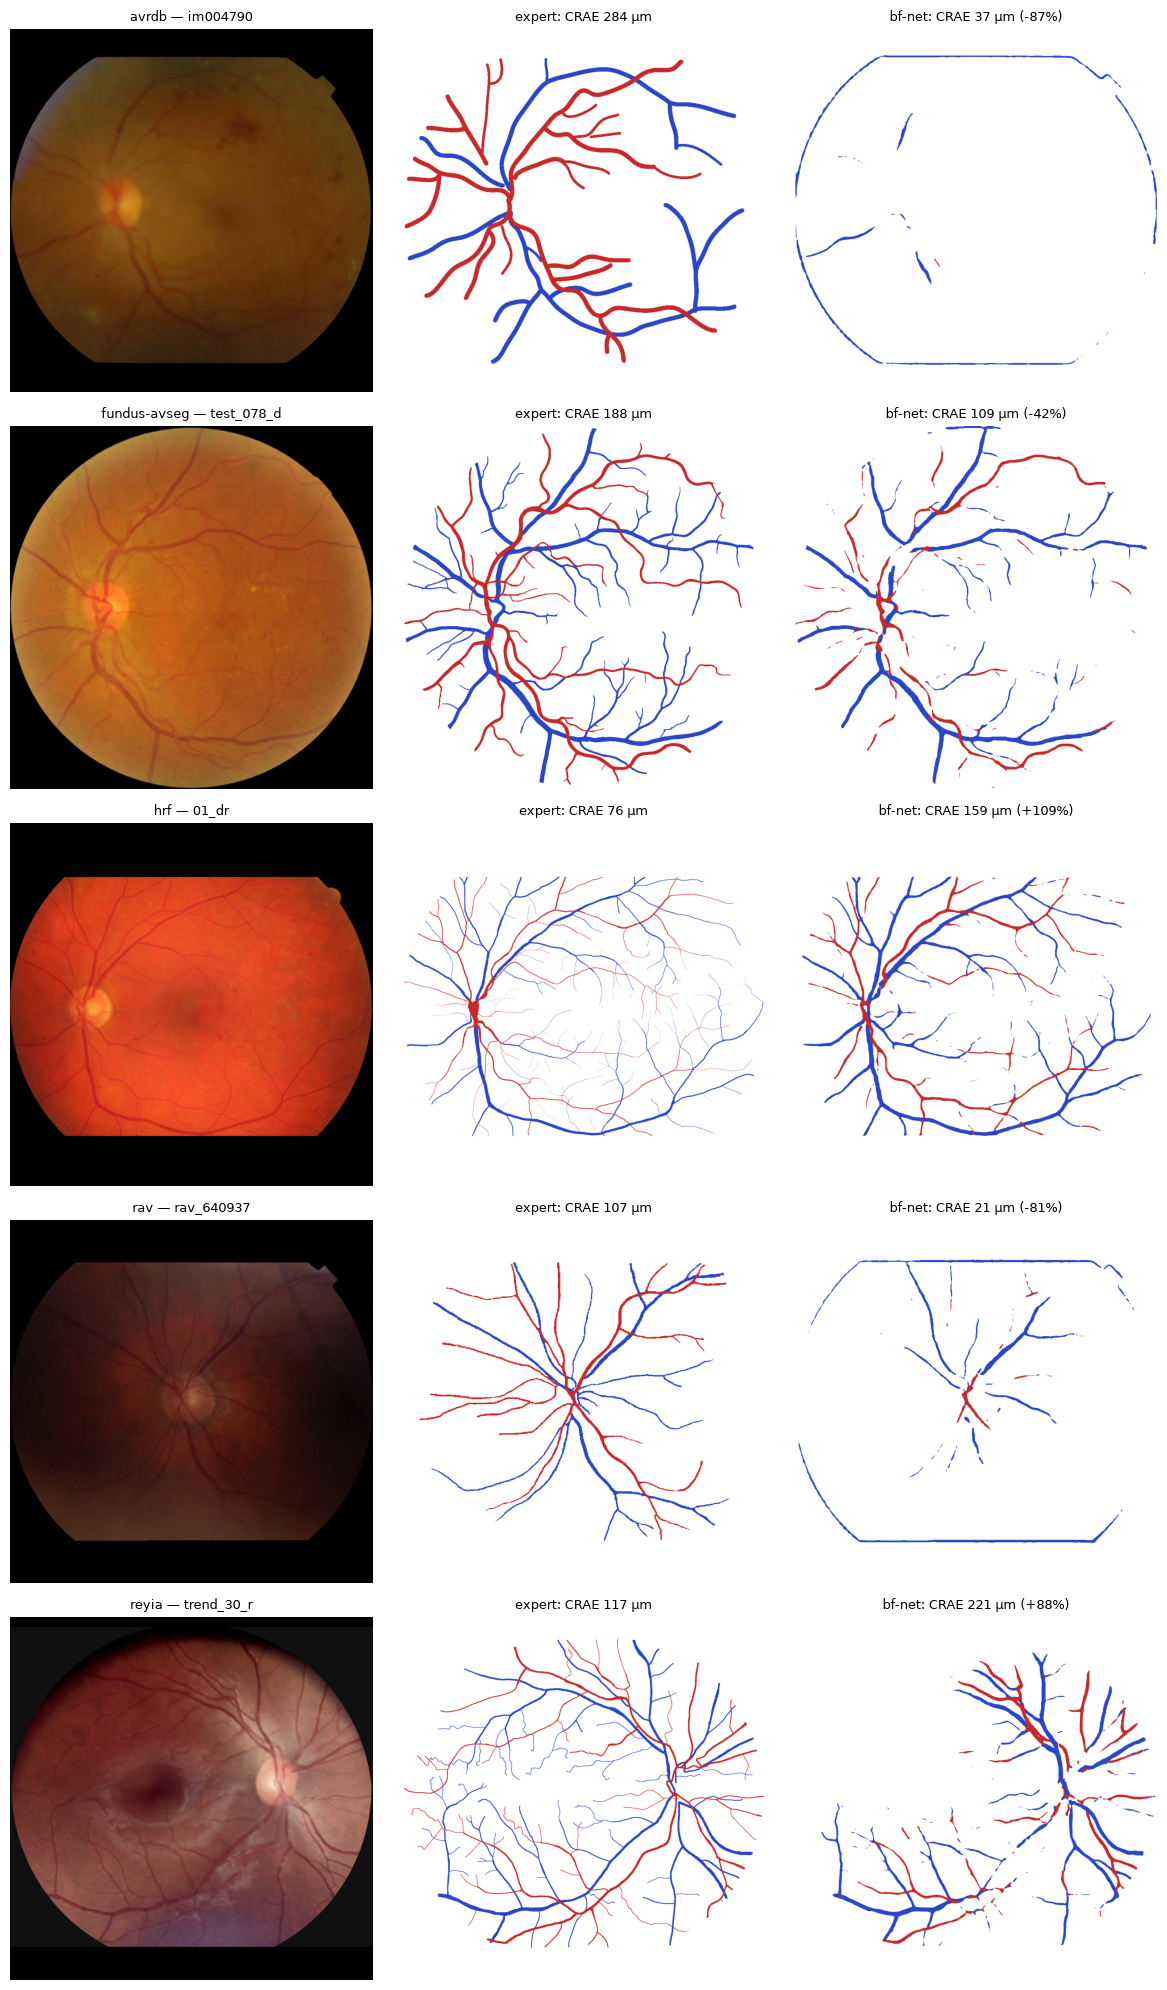

In [16]:
def painted(artery: np.ndarray, vein: np.ndarray) -> np.ndarray:
    canvas = np.full((*artery.shape, 3), 255, dtype=np.uint8)
    canvas[vein] = (40, 70, 200)
    canvas[artery] = (200, 40, 40)
    return canvas


def mask(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path)) > 0


crae = PAIRS["CRAE"].assign(moved=lambda f: (f["said"] - f["expert"]) / f["expert"])
worst = crae.loc[crae.groupby("dataset")["moved"].apply(lambda s: s.abs().idxmax())]

figure, axes = plt.subplots(len(worst), 3, figsize=(12, 4 * len(worst)), squeeze=False)
for row, (_, case) in enumerate(worst.iterrows()):
    crop = STORE / case["dataset"] / "crop"
    photo = np.asarray(Image.open(crop / "images" / f"{case['key']}.png").convert("RGB"))
    expert = painted(mask(crop / "artery" / f"{case['key']}.png"), mask(crop / "vein" / f"{case['key']}.png"))
    kept = KEPT / case["model"] / case["dataset"]
    model = painted(mask(kept / f"{case['key']}-artery.png"), mask(kept / f"{case['key']}-vein.png"))
    for column, (title, picture) in enumerate((
        (f"{case['dataset']} — {case['key']}", photo),
        (f"expert: CRAE {case['expert']:.0f} µm", expert),
        (f"{case['model']}: CRAE {case['said']:.0f} µm ({100 * case['moved']:+.0f}%)", model),
    )):
        axes[row, column].imshow(picture)
        axes[row, column].set_title(title, fontsize=9)
        axes[row, column].axis("off")
figure.tight_layout()
plt.show()

## 6. What it costs

Seconds per map for each implementation, averaged over every map it measured, on one core of this
machine. This measures the machine as much as the program. The models' own segmentation time is in
the artery/vein benchmark.

In [17]:
SUMMARY.pivot_table(index="implementation", columns="dataset", values="seconds_per_map", aggfunc="first").reindex(IMPLEMENTATIONS).round(1)

dataset,avrdb,fundus-avseg,hrf,rav,reyia
implementation,,,,,
pvbm,24.6,48.9,235.2,23.7,62.3
ocular,3.2,6.8,31.3,3.1,8.1
automorph,10.7,9.4,11.6,11.3,6.3
automorphalyzer,6.1,15.3,82.1,6.3,22.4
automorphclass,0.5,1.1,6.8,0.5,1.3
vascx,3.7,7.6,34.2,3.1,7.7
fundus-biomarkers,7.3,16.8,68.9,5.6,12.6


## 7. What the benchmark cannot say

### 7.1 Contamination

A model trained on a dataset's own annotations has seen these expert maps. Its ICC there measures
how well it reproduces its training labels, not how it would fare on a new cohort. The marks are
the run's own, per model and dataset.

In [18]:
marks = PER_DATASET[PER_DATASET["implementation"] == REFERENCE].drop_duplicates(["model", "dataset"]).pivot(
    index="model", columns="dataset", values="contamination").reindex(index=MODELS, columns=DATASETS)
marks

dataset,hrf,fundus-avseg,avrdb,reyia,rav
model,,,,,
vascx-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,in-sample-unclear-split
ocularnet,in-sample-unclear-split,in-sample-unclear-split,in-sample-unclear-split,"mixed: in-sample, out-of-sample",out-of-sample
lunet,unknown,unknown,unknown,unknown,unknown
automorph-artery-vein,in-sample-unclear-split,out-of-sample,out-of-sample,out-of-sample,out-of-sample
bf-net,out-of-sample,out-of-sample,out-of-sample,out-of-sample,out-of-sample


### 7.2 Out-of-sample only

The panel ICC(A,1) per model, over the datasets where that model is marked `out-of-sample`, set
beside its pooled figure. A grouping the run does not make, so it is computed here by the run's
own function, over the same pairs.

In [19]:
clean = {}
for label, pairs in PAIRS.items():
    for model in MODELS:
        out = [d for d in DATASETS if marks.loc[model, d] == "out-of-sample"]
        mine = pairs[(pairs["model"] == model) & pairs["dataset"].isin(out)]
        found = agreement.summary(list(mine["expert"]), list(mine["said"]))
        clean[(model, label)] = {"ICC(A,1) out-of-sample": found.get("icc_agreement"), "n": found["n"],
                                 "datasets": ", ".join(out) or "—"}
clean = pd.DataFrame(clean).T
clean["ICC(A,1) pooled"] = [pooled_panel.loc[m, ("ICC(A,1)", l)] for m, l in clean.index]
clean.astype({"n": int}).round(2)

,,"ICC(A,1) out-of-sample",n,datasets,"ICC(A,1) pooled"
vascx-artery-vein,CRAE,0.430452,684,"fundus-avseg, avrdb, reyia",0.49
ocularnet,CRAE,0.779224,155,rav,0.83
lunet,CRAE,None,0,—,0.35
automorph-artery-vein,CRAE,0.407657,832,"fundus-avseg, avrdb, reyia, rav",0.41
bf-net,CRAE,0.284041,852,"hrf, fundus-avseg, avrdb, reyia, rav",0.28
vascx-artery-vein,CRVE,0.560791,684,"fundus-avseg, avrdb, reyia",0.63
ocularnet,CRVE,0.864953,155,rav,0.87
lunet,CRVE,None,0,—,0.46
automorph-artery-vein,CRVE,0.558098,836,"fundus-avseg, avrdb, reyia, rav",0.56
bf-net,CRVE,0.327236,870,"hrf, fundus-avseg, avrdb, reyia, rav",0.33


### 7.3 REYIA by subset

REYIA is a compilation of collections from different cameras and clinics. CRAE ICC(A,1) per
subset shows whether one collection drives the dataset's figure.

In [20]:
subsets = {}
reyia_rows = {(row["key"]): row["subset"] for row in evidence(REFERENCE, "reyia") if row["source"] == "expert"} if (RESULTS / REFERENCE / "reyia.csv").exists() else {}
for label in ("CRAE", "AVR", "Artery fractal dimension"):
    pairs = PAIRS[label]
    pairs = pairs[pairs["dataset"] == "reyia"].assign(subset=lambda f: f["key"].map(reyia_rows))
    for (model, subset), group in pairs.groupby(["model", "subset"]):
        found = agreement.summary(list(group["expert"]), list(group["said"]))
        subsets[(model, subset, label)] = found.get("icc_agreement")
if subsets:
    subset_table = pd.Series(subsets).unstack(-1)
    display(subset_table.round(2))
else:
    print(f"no REYIA evidence in {RESULTS / REFERENCE}: run `--benchmark {benchmark.NAME} --dataset reyia`")

AVR  Artery fractal dimension  CRAE
automorph-artery-vein enrich    0.80                      0.71  0.84
                      fives     0.73                      0.51  0.76
                      grape     0.62                      0.57  0.69
                      mbrset    0.24                      0.51  0.74
                      messidor  0.83                      0.69  0.69
                      papila    0.13                      0.15  0.33
                      trend     0.06                      0.33  0.65
bf-net                enrich    0.19                      0.14  0.26
                      fives     0.28                      0.18  0.42
                      grape     0.26                      0.36  0.32
                      mbrset    0.16                      0.21  0.34
                      messidor  0.62                      0.35  0.13
                      papila    0.04                     -0.00  0.06
                      trend    -0.05                      0.19  0.18
lunet                 enrich    0.93                      0.92  0.97
                      fives     0.89                      0.76  0.97
                      grape     0.94                      0.75  0.96
                      mbrset   -0.04                      0.21  0.11
                      messidor  0.79                      0.77  0.88
                      papila    0.69                      0.85  0.89
                      trend     0.15                      0.13  0.44
ocularnet             enrich    0.89                      0.83  0.94
                      fives     0.92                      0.76  0.89
                      grape     0.90                      0.80  0.91
                      mbrset    0.30                      0.66  0.69
                      messidor  0.95                      0.78  0.82
                      papila    0.75                      0.89  0.88
                      trend     0.41                      0.47  0.58
vascx-artery-vein     enrich    0.81                      0.78  0.89
                      fives     0.84                      0.44  0.87
                      grape     0.79                      0.49  0.86
                      mbrset    0.68                      0.58  0.84
                      messidor  0.93                      0.42  0.88
                      papila    0.55                      0.27  0.65
                      trend     0.20                      0.41  0.56

### 7.4 Without AVRDB

AVRDB's expert maps are drawn with strokes about 1.6 times wider than the vessels any model traces
(the [artery/vein results](../docs/benchmarks/av-results.md) §4.1), and its points sit off the
diagonal for every model in section 2.3. Its rows measure how closely a model reproduces a
wide-stroke drawing. It stays in every pooled figure above; this table shows how much it moves them.
A grouping the run does not make, computed by the run's own function over the same pairs.

In [21]:
without = {}
for label, pairs in PAIRS.items():
    for model in MODELS:
        mine = pairs[(pairs["model"] == model) & (pairs["dataset"] != "avrdb")]
        found = agreement.summary(list(mine["expert"]), list(mine["said"]))
        without[(model, label)] = found.get("icc_agreement")
without = pd.Series(without).unstack()[list(PANEL)].reindex(MODELS)
pd.concat({"ICC(A,1) without AVRDB": without, "ICC(A,1) pooled": pooled_panel["ICC(A,1)"]}, axis=1).round(2)

ICC(A,1) without AVRDB              \
                                        CRAE  CRVE   AVR   
vascx-artery-vein                       0.77  0.83  0.65   
ocularnet                               0.81  0.85  0.76   
lunet                                   0.68  0.79  0.36   
automorph-artery-vein                   0.62  0.74  0.50   
bf-net                                  0.31  0.31  0.24   

                                                                  \
                      Artery fractal dimension Artery tortuosity   
vascx-artery-vein                         0.75              0.81   
ocularnet                                 0.91              0.89   
lunet                                     0.84              0.84   
automorph-artery-vein                     0.64              0.82   
bf-net                                    0.26              0.64   

                      ICC(A,1) pooled                                       \
                                 CRAE  CRVE   AVR Artery fractal dimension   
vascx-artery-vein                0.49  0.63  0.55                     0.38   
ocularnet                        0.83  0.87  0.73                     0.80   
lunet                            0.35  0.46  0.33                     0.41   
automorph-artery-vein            0.41  0.56  0.42                     0.31   
bf-net                           0.28  0.33  0.21                     0.10   

                                         
                      Artery tortuosity  
vascx-artery-vein                  0.81  
ocularnet                          0.88  
lunet                              0.83  
automorph-artery-vein              0.80  
bf-net                             0.63

### 7.5 On the photographs OCULARNet did not train on

OCULARNet trained on four of these five datasets and six of REYIA's eight subsets, so most of its
figures above are in-sample. REYIA's mBRSET and TREND-AV subsets, and RAV, are the photographs it
never saw. Every model on the same held-out photographs, so the comparison is like for like. VascX's
model is in-sample on RAV; LUNet's training data is unknown.

In [22]:
held_out_rows = []
for label, pairs in PAIRS.items():
    reyia_pairs = pairs[pairs["dataset"] == "reyia"].assign(subset=lambda f: f["key"].map(reyia_rows))
    for group, chosen in (
        ("reyia: mbrset + trend", reyia_pairs[reyia_pairs["subset"].isin(["mbrset", "trend"])]),
        ("rav", pairs[pairs["dataset"] == "rav"]),
    ):
        for model in MODELS:
            mine = chosen[chosen["model"] == model]
            found = agreement.summary(list(mine["expert"]), list(mine["said"]))
            held_out_rows.append({"photographs": group, "model": model, "biomarker": label,
                                  "icc": found.get("icc_agreement"), "n": found["n"]})
held_out = pd.DataFrame(held_out_rows)
table = held_out.pivot_table(index=["model", "photographs"], columns="biomarker", values="icc", aggfunc="first")[list(PANEL)]
display(table.reindex(pd.MultiIndex.from_product([MODELS, ["rav", "reyia: mbrset + trend"]], names=["model", "photographs"])).round(2))
held_out.pivot_table(index="photographs", values="n", aggfunc="max")

biomarker                                    CRAE  CRVE   AVR  \
model                 photographs                               
vascx-artery-vein     rav                    0.87  0.89  0.47   
                      reyia: mbrset + trend  0.69  0.72  0.54   
ocularnet             rav                    0.78  0.86  0.66   
                      reyia: mbrset + trend  0.69  0.57  0.40   
lunet                 rav                    0.78  0.79  0.60   
                      reyia: mbrset + trend  0.35  0.55 -0.07   
automorph-artery-vein rav                    0.77  0.80  0.46   
                      reyia: mbrset + trend  0.68  0.72  0.11   
bf-net                rav                    0.51  0.56  0.36   
                      reyia: mbrset + trend  0.39  0.23 -0.14   

biomarker                                    Artery fractal dimension  \
model                 photographs                                       
vascx-artery-vein     rav                                        0.56   
                      reyia: mbrset + trend                      0.47   
ocularnet             rav                                        0.75   
                      reyia: mbrset + trend                      0.56   
lunet                 rav                                        0.63   
                      reyia: mbrset + trend                      0.18   
automorph-artery-vein rav                                        0.25   
                      reyia: mbrset + trend                      0.41   
bf-net                rav                                        0.28   
                      reyia: mbrset + trend                      0.23   

biomarker                                    Artery tortuosity  
model                 photographs                               
vascx-artery-vein     rav                                 0.74  
                      reyia: mbrset + trend               0.66  
ocularnet             rav                                 0.92  
                      reyia: mbrset + trend               0.70  
lunet                 rav                                 0.81  
                      reyia: mbrset + trend               0.49  
automorph-artery-vein rav                                 0.83  
                      reyia: mbrset + trend               0.63  
bf-net                rav                                 0.60  
                      reyia: mbrset + trend               0.43

,n
photographs,
rav,155
reyia: mbrset + trend,75


### 7.6 What no number here says

- **Nothing about the reference's own noise.** Each dataset has one expert. A model disagreeing
  with that expert by about as much as a second expert would has matched the reference, not failed
  it. Without a second reader, where that ceiling sits is unknown.
- **Nothing about whether a program is right.** Two maps agreeing under one program says the
  program is stable to the change of map. Whether it computes what it claims is the synthetic
  benchmark's question.
- **Nothing about the disc.** Both maps of a photograph share one disc estimate, so a wrong disc
  moves both numbers alike and is invisible here.
- **A length on a photograph with no scale** is left out of its statistic. REYIA's `magreb`
  subset and part of RAV have none.